# Esperienza 9 — Tenuta pneumatica del sistema cilindro-pistone

### Scopo
Si verifica la **tenuta pneumatica** del sistema cilindro-pistone, cioè si misurano le perdite d'aria in funzione della sovrapressione del gas. Il sistema non è perfettamente a tenuta: il pistone in grafite scorre nel cilindro in pyrex quasi senza attrito, ma lascia filtrare un po' d'aria. Conoscere queste perdite serve a stimare gli effetti sistematici nelle esperienze successive, in cui si assume che il numero di moli resti costante.

### Procedura (dalla scheda)
1. Il cilindro è verticale, con il pistone a metà corsa, collegato con un filo alla puleggia del sensore di moto rotatorio CI-6538, che ne misura la posizione $h$.
2. Si appoggia sul pistone un pesetto di massa $m$, misurata con la bilancia. La pressione del gas aumenta di
$$\Delta p = \frac{mg}{S},$$
   dove $S$ è la superficie del pistone.
3. A causa delle perdite il gas esce e il pistone scende lentamente. Si acquisisce $h(t)$ per circa un minuto: l'andamento è circa lineare, con pendenza $\alpha = dh/dt$.
4. La variazione di volume per unità di tempo è
$$\beta = \alpha \cdot S \quad [\mathrm{cm^3/min}],$$
   che a pressione e temperatura costanti è proporzionale alla quantità di gas persa per unità di tempo.
5. Si ripete con masse diverse (almeno 4 punti) e si fa il grafico di $\beta$ in funzione di $\Delta p = mg/S$. L'andamento è circa lineare, e la pendenza
$$\omega = \frac{d\beta}{d(\Delta p)} \quad \left[\frac{\mathrm{cm^3}}{\mathrm{kPa\cdot min}}\right]$$
   caratterizza la tenuta del sistema.
6. Si ripete tutto collegando anche il **cilindro di metallo** al sistema, e si confrontano i due valori di $\omega$.

Anche senza pesetto il pistone scende, perché il suo peso stesso produce una sovrapressione: per questo nel fit $\beta = \omega\,\Delta p + c$ ci si aspetta un'intercetta $c > 0$.

### Preparazione dell'ambiente
Le prime celle importano i moduli e fissano la cartella di lavoro.


In [28]:
import sys
import os

Nel notebook `__file__` non esiste: la cartella di lavoro è quella del notebook (`9/`). I percorsi dei dati (`9/POS-9-1.txt`, ...) e il modulo `info.py` sono relativi a `PP2`. Se `info.py` non si trova nella cartella corrente si sale di un livello, e la cartella si aggiunge a `sys.path` per poter fare `import info`.


In [29]:
# Nel notebook __file__ non esiste: la cartella di lavoro e' quella del notebook.
# I percorsi dei dati (e il modulo info) sono relativi a PP2, quindi ci si sposta li'.
if not os.path.exists("info.py"):
    os.chdir("..")
sys.path.append(os.getcwd())

Il modulo `info` contiene risoluzione e accuracy degli strumenti della postazione (bilancia Kern FCB 3K0.1, sensore di posizione CI-6538, sensore di pressione CI-6534). Ovunque l'incertezza di tipo B è
$$\sigma_B = \sqrt{\left(\frac{\text{risoluzione}}{\sqrt{12}}\right)^2 + \text{accuracy}^2}.$$
- La **risoluzione** entra divisa per $\sqrt{12}$: l'errore di lettura è distribuito uniformemente su un intervallo largo quanto la risoluzione.
- L'**accuracy** si tiene su ogni lettura. Non si può trattare come un offset da eliminare, perché la curva di risposta dello strumento non è nota.


In [30]:
import matplotlib.pyplot as plt
import numpy as np
import info

### Funzioni di supporto
#### Lettura dei file
DataStudio esporta i dati con la **virgola** come separatore decimale, che `numpy` non riconosce. `comma_to_float` sostituisce la virgola con il punto (decodificando prima i `bytes` in `latin1`).


In [31]:
def comma_to_float(x):
    if isinstance(x, bytes):
        x = x.decode('latin1')
    return float(x.replace(',', '.'))

`carica(percorso)` legge un file esportato da DataStudio (due righe di intestazione, due colonne: tempo e grandezza misurata) e restituisce i due array. Si usa sia per i file di posizione `POS-*.txt` sia per quelli di pressione `PRES-*.txt`.


In [32]:
def carica(percorso):
    return np.loadtxt(percorso, unpack=True, skiprows=2, encoding='latin1',
                      converters={0: comma_to_float, 1: comma_to_float})

#### Inizio del tratto utile: `trova_inizio`
Quando si appoggia il pesetto, il pistone ha un **transitorio**: scende di colpo, rimbalza e oscilla prima di assestarsi nella discesa lenta dovuta alle perdite. Il fit di $h(t)$ va fatto solo dopo questo transitorio.
- `idx_massa` è il primo punto in cui la posizione differisce dal valore iniziale (il momento in cui si appoggia il pesetto).
- `idx_inizio` è il primo punto, dopo `idx_massa`, da cui la posizione resta **costante per almeno `durata_stabile` secondi** (0.5 s). Il pistone si è fermato dopo il rimbalzo, e da lì in poi c'è solo la discesa lenta.

`tol = 1e-9` serve solo a confrontare numeri in virgola mobile: la posizione è quantizzata, quindi "costante" significa "sullo stesso gradino".


In [33]:
def trova_inizio(t, pos, durata_stabile=0.5, tol=1e-9):
    """
    Restituisce (idx_massa, idx_inizio):
      idx_massa  -> primo punto in cui la posizione cambia (massa appoggiata)
      idx_inizio -> primo punto dopo il rimbalzo da cui la posizione
                    resta costante per almeno `durata_stabile` secondi
    """
    variati = np.flatnonzero(np.abs(pos - pos[0]) > tol)
    if len(variati) == 0:
        return 0, 0
    idx_massa = variati[0]

    dt = np.median(np.diff(t))
    n = max(int(round(durata_stabile / dt)), 2)

    for k in range(idx_massa, len(pos) - n):
        if np.all(np.abs(pos[k:k + n] - pos[k]) < tol):
            return idx_massa, k

    return idx_massa, idx_massa

#### Banda di confidenza del fit: `banda_fit`
Per la retta $y = a x + b$ con matrice di covarianza dei parametri $\mathrm{cov}$, l'incertezza della retta in un punto $x$ si ricava propagando con le correlazioni:
$$\sigma_y(x) = \sqrt{x^2\,\sigma_a^2 + \sigma_b^2 + 2x\,\mathrm{cov}(a,b)}.$$
Il termine di covarianza è importante: pendenza e intercetta sono quasi sempre correlate (negativamente se le $x$ sono positive), e trascurarlo darebbe una banda sbagliata.


In [34]:
def banda_fit(x, cov):
    """Incertezza a 1 sigma della retta y = a x + b in ogni punto x."""
    return np.sqrt(x**2 * cov[0, 0] + cov[1, 1] + 2 * x * cov[0, 1])

### Parametri
- `CARTELLA`: sottocartella con i dati di questa esperienza.
- `g = 9.81 m/s²`: accelerazione di gravità, per calcolare $\Delta p = mg/S$. La sua incertezza è trascurabile rispetto alle altre.


In [35]:
CARTELLA = "9/data"
g = 9.81  # m/s^2

### Bilancia Kern FCB 3K0.1
Risoluzione e accuracy della bilancia si prendono da `info`. Si tengono separate, invece di usare direttamente `sigma_b_massa`, perché entrano in modo diverso quando si sommano più pesetti (vedi le masse cumulative).


In [36]:
RIS_MASSA_g = info.risoluzione_massa_FCB3K01    # g
ACC_MASSA_g = info.accuracy_massa_FCB3K01       # g

### Pesate ripetute dei singoli pesetti [g]
Ogni pesetto è stato pesato 4 volte. La sua massa è la **media** delle pesate, e la parte statistica dell'incertezza è la deviazione standard **della media**:
$$\bar m_j = \frac{1}{n}\sum_k m_{j,k}, \qquad \sigma_{A,j} = \frac{s_j}{\sqrt{n}}, \qquad n = 4.$$
Si divide per $\sqrt{n}$ perché il valore usato poi è la media, non la singola pesata.


In [37]:
PESATE_g = [
    [83.3, 83.7, 83.8, 83.8],   # pesetto 1
    [84.3, 84.1, 84.2, 84.0],   # pesetto 2
    [83.2, 83.1, 83.2, 83.2],   # pesetto 3
    [82.0, 81.9, 82.0, 82.2],   # pesetto 4
]

medie_pesetti = np.array([np.mean(x) for x in PESATE_g])
sigma_a_pesetti = np.array([np.std(x, ddof=1) / np.sqrt(len(x)) for x in PESATE_g])

#### Masse cumulative
I pesetti si aggiungono uno alla volta: nel file $k$-esimo sul pistone ci sono i pesetti $1, \dots, k$ (il primo file è senza pesetti). La massa totale è
$$M_k = \sum_{j=1}^{k} \bar m_j.$$
L'incertezza su $M_k$ ha tre contributi:
- **statistico** delle pesate: le medie dei singoli pesetti sono indipendenti, quindi si sommano in quadratura, $\sum_j \sigma_{A,j}^2$;
- **risoluzione**: ogni pesetto è una lettura diversa della bilancia, quindi si sommano in quadratura $k$ termini $(\text{ris}/\sqrt{12})^2$;
- **accuracy**: è la stessa bilancia per tutti i pesetti, quindi l'errore è **correlato**, va nello stesso verso su tutti, e si somma **linearmente**: $k \cdot \text{acc}$.

In totale:
$$\sigma_{M_k} = \sqrt{\sum_{j=1}^{k}\sigma_{A,j}^2 + k\left(\frac{\text{ris}}{\sqrt{12}}\right)^2 + \big(k\cdot\text{acc}\big)^2}.$$


In [38]:
# Masse cumulative: nel file k ci sono i pesetti 1..k (il primo file e' senza massa)
masse_cum = [0.0]
sigma_masse_cum = [0.0]
for k in range(1, len(PESATE_g) + 1):
    masse_cum.append(medie_pesetti[:k].sum())
    sigma_stat = np.sqrt(np.sum(sigma_a_pesetti[:k]**2) + k * (RIS_MASSA_g / np.sqrt(12))**2)
    sigma_acc = k * ACC_MASSA_g      # stessa bilancia: sistematico, si somma linearmente
    sigma_masse_cum.append(np.sqrt(sigma_stat**2 + sigma_acc**2))

Stampa di controllo: massa media e incertezza statistica di ogni pesetto, poi le masse cumulative con l'incertezza totale.


In [39]:
print("Pesetti:")
for j, (mj, sj) in enumerate(zip(medie_pesetti, sigma_a_pesetti), 1):
    print(f"  pesetto {j}: {mj:.3f} g (sigma_A = {sj:.3f} g)")

Pesetti:
  pesetto 1: 83.650 g (sigma_A = 0.119 g)
  pesetto 2: 84.150 g (sigma_A = 0.065 g)
  pesetto 3: 83.175 g (sigma_A = 0.025 g)
  pesetto 4: 82.025 g (sigma_A = 0.063 g)


In [40]:
print("Masse cumulative:")
for k, (mk, sk) in enumerate(zip(masse_cum, sigma_masse_cum)):
    print(f"  file {k + 1}: m = {mk:.3f} ± {sk:.3f} g")

Masse cumulative:
  file 1: m = 0.000 ± 0.000 g
  file 2: m = 83.650 ± 0.324 g
  file 3: m = 167.800 ± 0.616 g
  file 4: m = 250.975 ± 0.912 g
  file 5: m = 333.000 ± 1.211 g


### Pistone
La superficie del pistone è $S = \pi (D/2)^2$. Propagando l'incertezza sul diametro,
$$\frac{\sigma_S}{S} = 2\,\frac{\sigma_D}{D}.$$
$D$ e $\sigma_D$ sono segnati come **da verificare**: vanno controllati sulla scheda tecnica o misurati con il calibro. $S$ compare sia in $\Delta p$ sia in $\beta$, quindi la sua incertezza si tratta a parte, come errore sistematico comune su $\omega$ (vedi più avanti).


In [41]:
D_PISTONE = 32.5e-3               # m   <-- VERIFICARE
SIGMA_D   = 0.1e-3                # m   <-- incertezza sul diametro
S         = np.pi * (D_PISTONE / 2)**2
SIGMA_S   = S * 2 * SIGMA_D / D_PISTONE

### Sensore di posizione CI-6538
- `RIS_POS_NOMINALE` è la risoluzione nominale da `info`, $2\pi r/1440$ con la puleggia media. Si usa solo se dai dati non si riesce a ricavare il passo effettivo.
- `ACC_REL_POSIZIONE`: un errore di **scala** del sensore (per esempio sul raggio della puleggia impostato in DataStudio) moltiplica tutte le posizioni per lo stesso fattore, quindi agisce come errore **relativo** sulla pendenza $\alpha$. Per ora è 0; se si conosce $\sigma_r/r$ va inserito qui.


In [42]:
# risoluzione nominale da info (usata solo se dai dati non si ricava il passo)
RIS_POS_NOMINALE = info.risoluzione_posizione_CI6538 * 1e-3      # m
# info.accuracy_posizione_CI6538 = 0 e' un offset assoluto: non influisce sulla pendenza.
# Per alpha conta solo un errore di scala (es. sul raggio della puleggia):
ACC_REL_POSIZIONE = 0.0           # <-- es. sigma_raggio / raggio, se nota

### Sensore di pressione CI-6534 (solo per il controllo)
La pressione misurata non entra nel calcolo di $\omega$, che usa $\Delta p = mg/S$, ma serve come **controllo**: la pressione letta dal sensore durante ogni prova si confronta con $mg/S$. L'incertezza su ogni lettura è $\sigma_B$ completa da `info`, cioè risoluzione/$\sqrt{12}$ e accuracy: qui si confrontano valori assoluti di pressione, quindi l'accuracy conta pienamente.

`M3S_TO_CM3MIN` converte $\beta$ da $\mathrm{m^3/s}$ a $\mathrm{cm^3/min}$, l'unità chiesta dalla scheda ($10^6$ cm³/m³ × 60 s/min).


In [43]:
SIGMA_B_P = info.sigma_b_pressione_CI6534     # kPa (risoluzione + accuracy)

M3S_TO_CM3MIN = 1e6 * 60          # da m^3/s a cm^3/min

### Serie di misure
Ci sono due serie da 5 file ciascuna:
- **solo cilindro-pistone**: file `9-1` ... `9-5`;
- **con cilindro di metallo** collegato: file `9-2-1` ... `9-2-5`.

In entrambe il primo file è senza pesetti e i successivi hanno 1, 2, 3, 4 pesetti.


In [44]:
SERIE = {
    "Solo cilindro-pistone":   [f"9-{i}" for i in range(1, 6)],
    "Con cilindro di metallo": [f"9-2-{i}" for i in range(1, 6)],
}

Le due serie usano gli **stessi pesetti**, quindi le stesse masse cumulative e le stesse incertezze.


In [45]:
# stessi pesetti per entrambe le serie
MASSE_g = {nome: masse_cum for nome in SERIE}
SIGMA_MASSE_g = {nome: sigma_masse_cum for nome in SERIE}

### Analisi di un file
La funzione `analizza_file(nome, con_massa, massa_g, sigma_massa_g)` analizza una singola acquisizione e restituisce $\Delta p$, $\beta$ e la pressione misurata, ciascuno con la sua incertezza.

#### 1. Selezione del tratto
Se c'è un pesetto, con `trova_inizio` si scarta il transitorio dovuto all'appoggio. Senza pesetto si usa tutto il file.

#### 2. Incertezza sulla posizione
Il sensore restituisce posizioni **quantizzate**: il passo minimo (LSB) si ricava dai dati, come la più piccola differenza tra valori distinti di $h$. L'errore di quantizzazione è distribuito uniformemente su un LSB, quindi su ogni punto
$$\sigma_h = \frac{\text{LSB}}{\sqrt{12}}.$$
Si usa il passo dei dati e non quello nominale di `info` perché è quello effettivamente applicato da DataStudio con la configurazione usata.

#### 3. Fit $h(t) = \alpha t + q$
Fit lineare pesato con pesi uguali $1/\sigma_h$ e `cov='unscaled'`: l'incertezza su $\alpha$ viene da $\sigma_h$ e non dalla dispersione dei residui. All'incertezza del fit si somma in quadratura un eventuale errore di scala relativo (`ACC_REL_POSIZIONE`).

> **Nota.** In ogni file il pistone scende di pochi LSB, quindi $h$ assume pochi valori distinti. In queste condizioni gli errori di quantizzazione dei punti non sono indipendenti (formano una scala), e l'incertezza su $\alpha$ data dal fit può risultare sottostimata. Un $\chi^2$ grande nel fit di $\omega$ più avanti è un segnale di questo.

#### 4. Sovrapressione
$$\Delta p = \frac{mg}{S}, \qquad \sigma_{\Delta p} = \frac{g\,\sigma_m}{S},$$
convertita in kPa. In $\sigma_{\Delta p}$ si mette solo l'incertezza sulla massa: quella su $S$ è comune a tutti i punti e si tratta a parte su $\omega$.

#### 5. Perdita di volume
$$\beta = \alpha S, \qquad \sigma_\beta = \sigma_\alpha S,$$
convertita in cm³/min. Anche qui l'incertezza su $S$ resta fuori, per lo stesso motivo.

#### 6. Pressione misurata (controllo)
Dal momento in cui inizia il tratto analizzato, la pressione letta è la **media** dei campioni. La sua incertezza è la deviazione standard della media (tipo A) sommata in quadratura a $\sigma_B$, che non si riduce mediando:
$$\sigma_{p} = \sqrt{\left(\frac{s_p}{\sqrt{n}}\right)^2 + \sigma_B^2}.$$
Il CI-6534 misura già la pressione relativa all'ambiente.

#### 7. Grafici
- In alto: posizione nel tempo, con l'istante in cui si appoggia il pesetto (rosso), l'inizio dell'analisi (blu), la fascia $\pm\sigma_h$ sui dati, la retta di fit e la sua banda a $1\sigma$, calcolata con `banda_fit`.
- In basso: pressione nel tempo, con la fascia $\pm\sigma_B$ e la media con la sua incertezza.


In [ ]:
def analizza_file(nome, con_massa, massa_g, sigma_massa_g):
    t, h = carica(f"{CARTELLA}/POS-{nome}.txt")
    t_p, p = carica(f"{CARTELLA}/PRES-{nome}.txt")

    if con_massa:
        idx_massa, idx_inizio = trova_inizio(t, h)
    else:
        idx_massa, idx_inizio = None, 0

    t_sel, h_sel = t[idx_inizio:], h[idx_inizio:]

    # --- POSIZIONE: risoluzione dal passo dei dati, incertezza di quantizzazione
    passi = np.diff(np.unique(np.round(h, 12)))
    lsb = passi.min() if len(passi) > 0 else RIS_POS_NOMINALE
    sigma_h = lsb / np.sqrt(12)

    # FIT h(t) = alpha * t + q
    (alpha, q), cov_h = np.polyfit(t_sel, h_sel, 1,
                                   w=np.full(len(t_sel), 1 / sigma_h),
                                   cov='unscaled')
    sigma_alpha_ris = np.sqrt(cov_h[0, 0])
    # l'accuracy di scala del sensore agisce come errore relativo sulla pendenza
    sigma_alpha_acc = abs(alpha) * ACC_REL_POSIZIONE
    sigma_alpha = np.sqrt(sigma_alpha_ris**2 + sigma_alpha_acc**2)

    # --- MASSA e dp = m g / S (incertezza puntuale, senza S: S e' trattata a parte)
    m = massa_g * 1e-3
    sigma_m = sigma_massa_g * 1e-3
    dp = m * g / S / 1e3                     # kPa
    sigma_dp = g * sigma_m / S / 1e3         # kPa

    # --- BETA = alpha * S (incertezza puntuale, senza S)
    beta = alpha * S * M3S_TO_CM3MIN
    sigma_beta = sigma_alpha * S * M3S_TO_CM3MIN

    # --- CONTROLLO: pressione misurata dal sensore (gia' relativa all'ambiente)
    maschera = t_p >= t[idx_inizio]
    t_p_sel, p_sel = t_p[maschera], p[maschera]
    p_mis = p_sel.mean()
    sigma_p_mis = np.sqrt((p_sel.std(ddof=1) / np.sqrt(len(p_sel)))**2 + SIGMA_B_P**2)

    print(f"  {nome}: m = {massa_g:.2f} ± {sigma_massa_g:.2f} g | "
          f"mg/S = {dp:.4f} ± {sigma_dp:.4f} kPa | "
          f"p misurata = {p_mis:.4f} ± {sigma_p_mis:.4f} kPa")
    print(f"         alpha = ({alpha*1e6:.3f} ± {sigma_alpha*1e6:.3f}) um/s "
          f"[ris {sigma_alpha_ris*1e6:.3f}, acc {sigma_alpha_acc*1e6:.3f}] | "
          f"beta = {beta:.4f} ± {sigma_beta:.4f} cm^3/min")

    # ======================= GRAFICI =======================
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

    # --- Posizione
    if con_massa:
        ax1.plot(t, h * 1e3, color='gray', alpha=0.5, label='Dati completi')
        ax1.axvline(t[idx_massa], color='red', linestyle='--',
                    label=f'Massa appoggiata (t = {t[idx_massa]:.2f} s)')
        ax1.axvline(t[idx_inizio], color='blue', linestyle='--',
                    label=f'Inizio analisi (t = {t[idx_inizio]:.2f} s)')

    ax1.fill_between(t_sel, (h_sel - sigma_h) * 1e3, (h_sel + sigma_h) * 1e3,
                     color='black', alpha=0.15, step='mid',
                     label=f'Incertezza dati ±{sigma_h*1e3:.3f} mm (LSB/√12)')
    ax1.step(t_sel, h_sel * 1e3, where='mid', color='black', linewidth=1,
             label="Dati per l'analisi")

    h_fit = alpha * t_sel + q
    sigma_fit = banda_fit(t_sel, cov_h)
    ax1.plot(t_sel, h_fit * 1e3, color='orange',
             label=f'Fit: alpha = ({alpha*1e6:.2f} ± {sigma_alpha*1e6:.2f}) um/s')
    ax1.fill_between(t_sel, (h_fit - sigma_fit) * 1e3, (h_fit + sigma_fit) * 1e3,
                     color='orange', alpha=0.35, label='Banda del fit (1σ)')

    ax1.set_ylabel("Posizione h [mm]")
    ax1.set_title(f"Tenuta cilindro-pistone [{nome}] - m = {massa_g:.2f} ± {sigma_massa_g:.2f} g")
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)

    # --- Pressione
    ax2.plot(t_p, p, color='gray', alpha=0.5)
    ax2.fill_between(t_p_sel, p_sel - SIGMA_B_P, p_sel + SIGMA_B_P,
                     color='black', alpha=0.15,
                     label=f'Incertezza lettura ±{SIGMA_B_P:.3f} kPa (ris. + acc.)')
    ax2.plot(t_p_sel, p_sel, color='black', linewidth=1)
    ax2.axhline(p_mis, color='green', linestyle='--',
                label=f'p media = {p_mis:.3f} ± {sigma_p_mis:.3f} kPa')
    ax2.axhspan(p_mis - sigma_p_mis, p_mis + sigma_p_mis, color='green', alpha=0.2)
    ax2.set_xlabel("Tempo [s]")
    ax2.set_ylabel("Pressione relativa [kPa]")
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{CARTELLA}/{nome}_analisi.png", dpi=300)
    plt.show()

    return dp, sigma_dp, beta, sigma_beta, p_mis, sigma_p_mis

### FIT CON ERRORI SU x E y
Nel fit $\beta = \omega\,\Delta p + c$ entrambe le variabili hanno incertezza: $\Delta p$ attraverso la massa, $\beta$ attraverso $\alpha$. Il metodo dei minimi quadrati standard considera errori solo sulle $y$. Con il metodo della **varianza efficace** l'incertezza su $x$ si propaga sulle ordinate usando la pendenza della retta:
$$\sigma_{y,\text{eff}}^2 = \sigma_y^2 + \left(\frac{dy}{dx}\right)^2\sigma_x^2 = \sigma_y^2 + \omega^2\sigma_x^2.$$
Siccome $\sigma_{y,\text{eff}}$ dipende da $\omega$, che è ciò che si sta stimando, si procede per **iterazioni**:
1. un primo fit con le sole $\sigma_y$ dà una stima di $\omega$;
2. con questa stima si calcolano le $\sigma_{y,\text{eff}}$ e si rifà il fit;
3. si ripete il passo 2 (10 iterazioni sono più che sufficienti a convergere).

Alla fine si calcola il $\chi^2$ con le $\sigma_{y,\text{eff}}$ finali, per controllare la bontà del fit.

> Le masse cumulative condividono pesetti e accuracy della bilancia, quindi gli errori sulle $x$ sono in parte correlati tra i punti. Il metodo li tratta come indipendenti: è un'approssimazione.


In [47]:
def fit_lineare_xy(x, sx, y, sy, n_iter=10):
    """
    Fit y = a x + b con il metodo della varianza efficace:
    l'incertezza su x viene propagata sulle ordinate, sy_eff^2 = sy^2 + (a sx)^2.
    """
    a, b = np.polyfit(x, y, 1, w=1 / sy)
    for _ in range(n_iter):
        s_eff = np.sqrt(sy**2 + (a * sx)**2)
        (a, b), cov = np.polyfit(x, y, 1, w=1 / s_eff, cov='unscaled')
    s_eff = np.sqrt(sy**2 + (a * sx)**2)
    chi2 = np.sum(((y - (a * x + b)) / s_eff)**2)
    return a, b, cov, chi2, s_eff

### Analisi delle due serie
Per ogni serie:
1. si analizzano i 5 file con `analizza_file` (il primo senza pesetto, `con_massa=False`);
2. si fa il fit $\beta = \omega\,\Delta p + c$ con la varianza efficace;
3. si aggiunge a $\omega$ l'incertezza sistematica dovuta alla superficie del pistone.

#### Incertezza da $S$
$S$ compare in tutti e due gli assi: $\beta \propto S$ e $\Delta p \propto 1/S$. Quindi
$$\omega = \frac{d\beta}{d(\Delta p)} \propto \frac{S}{1/S} = S^2 \quad\Longrightarrow\quad \frac{\sigma_{\omega,S}}{\omega} = 2\,\frac{\sigma_S}{S}.$$
È un errore comune a tutti i punti, quindi non entra nel fit ma si somma dopo, in quadratura con l'incertezza del fit:
$$\sigma_\omega = \sqrt{\sigma_{\omega,\text{fit}}^2 + \sigma_{\omega,S}^2}.$$

#### Controllo sulla pressione
Il sensore misura la sovrapressione totale, dovuta al pesetto **e** al pistone. Quindi
$$p_\text{mis} - \frac{mg}{S} \approx \frac{m_\text{pistone}\,g}{S}$$
deve essere circa costante da un file all'altro, e dalla sua media si ricava una stima della massa del pistone. Se invece la differenza varia in modo sistematico con la massa, c'è un errore di scala tra le due misure di pressione: per esempio su $S$, oppure il guadagno del sensore ricavato nell'esperienza 8. Questo spiega anche perché $\beta \neq 0$ senza pesetti, e quindi perché l'intercetta $c$ è positiva.

`risultati` raccoglie, per ogni serie, i dati e i parametri del fit, usati nel grafico di confronto.


In [48]:
risultati = {}

Nella stampa dei "contributi a $\sigma_{\beta,\text{eff}}$" si confrontano, punto per punto, $\sigma_\beta$ (da $\alpha$) e $\omega\,\sigma_{\Delta p}$ (dalla massa propagata sulle ordinate). Così si vede quale dei due domina.



Solo cilindro-pistone
  9-1: m = 0.00 ± 0.00 g | mg/S = 0.0000 ± 0.0000 kPa | p misurata = 0.3438 ± 0.1020 kPa
         alpha = (4.046 ± 0.054) um/s [ris 0.054, acc 0.000] | beta = 0.2014 ± 0.0027 cm^3/min


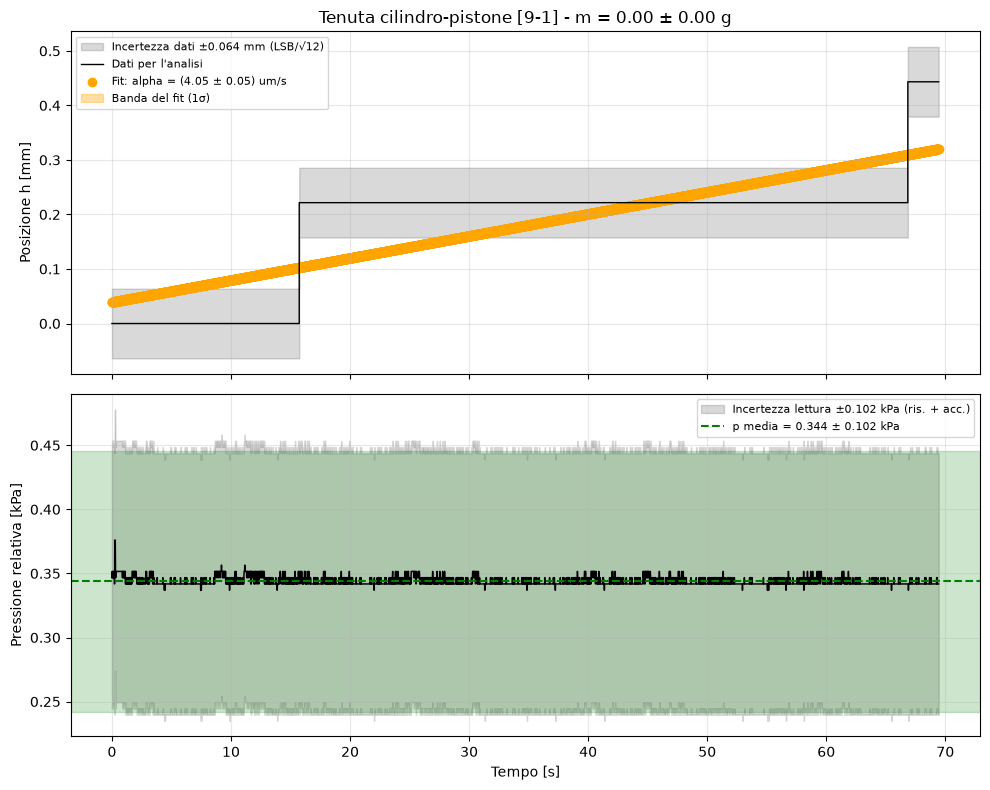

  9-2: m = 83.65 ± 0.32 g | mg/S = 0.9892 ± 0.0038 kPa | p misurata = 1.2236 ± 0.1020 kPa
         alpha = (12.277 ± 0.038) um/s [ris 0.038, acc 0.000] | beta = 0.6111 ± 0.0019 cm^3/min


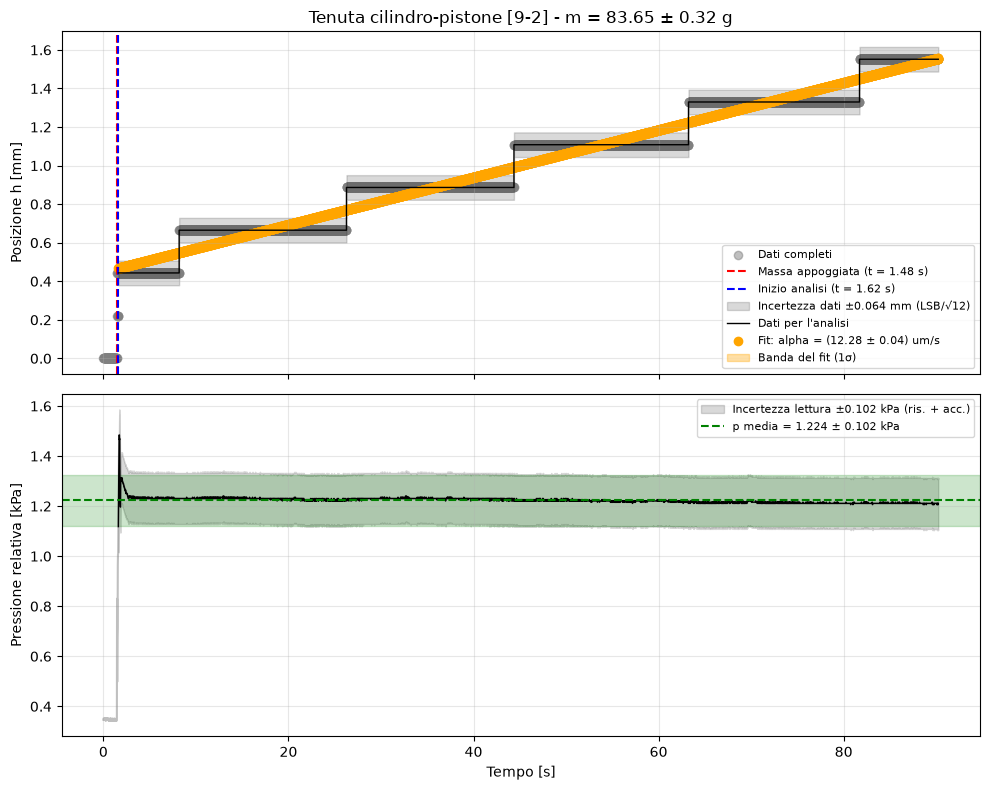

  9-3: m = 167.80 ± 0.62 g | mg/S = 1.9843 ± 0.0073 kPa | p misurata = 2.1013 ± 0.1020 kPa
         alpha = (21.232 ± 0.070) um/s [ris 0.070, acc 0.000] | beta = 1.0568 ± 0.0035 cm^3/min


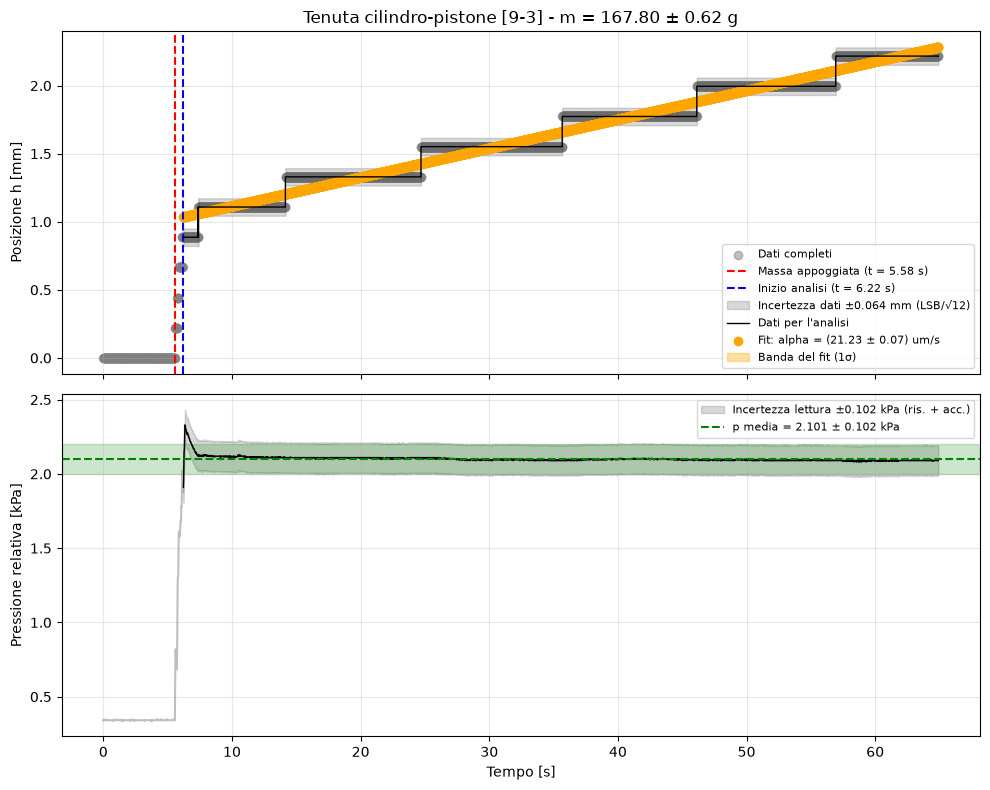

  9-4: m = 250.98 ± 0.91 g | mg/S = 2.9679 ± 0.0108 kPa | p misurata = 3.1210 ± 0.1020 kPa
         alpha = (35.600 ± 0.067) um/s [ris 0.067, acc 0.000] | beta = 1.7720 ± 0.0033 cm^3/min


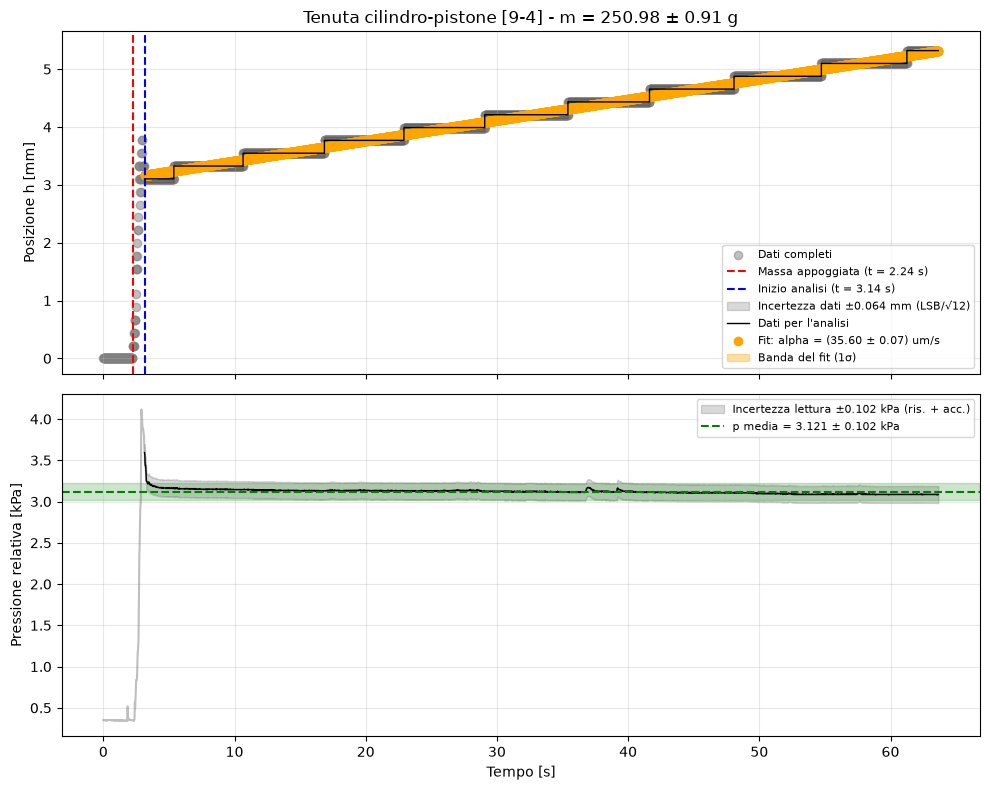

  9-5: m = 333.00 ± 1.21 g | mg/S = 3.9378 ± 0.0143 kPa | p misurata = 4.0539 ± 0.1020 kPa
         alpha = (46.196 ± 0.062) um/s [ris 0.062, acc 0.000] | beta = 2.2994 ± 0.0031 cm^3/min


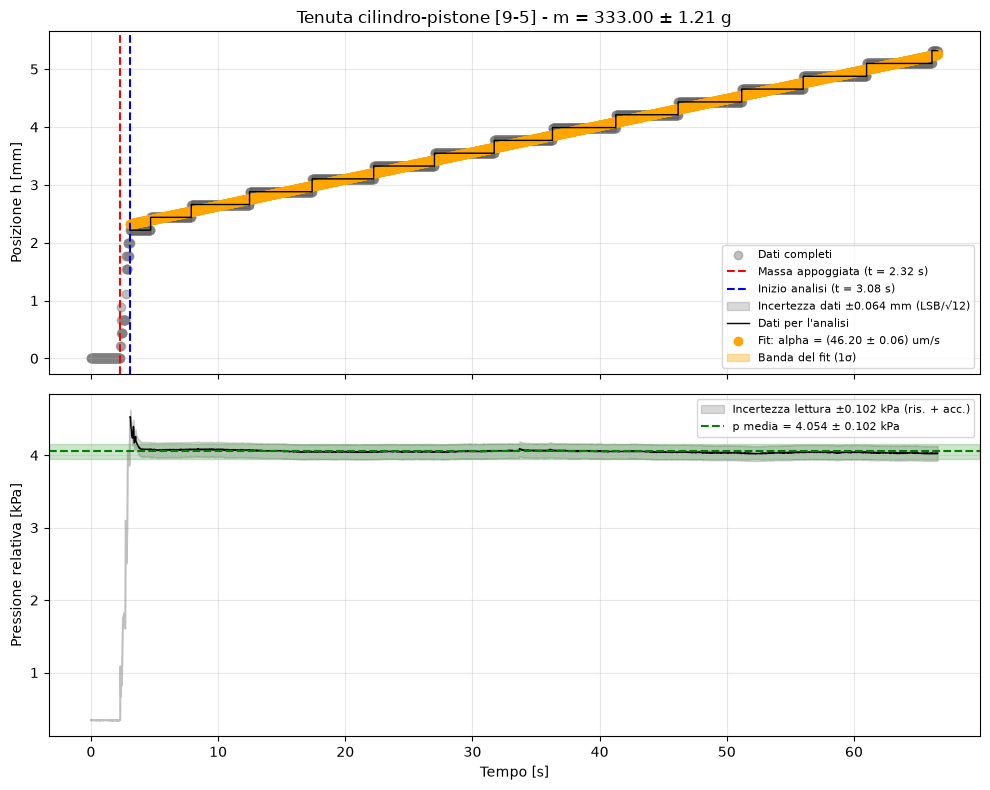

  Contributi a sigma_beta_eff: sigma_beta = [0.0027  0.00187 0.00347 0.00331 0.00308], omega*sigma_dp = [0.      0.00196 0.00373 0.00552 0.00733] cm^3/min
  omega = 0.5119 ± 0.0065 cm^3/(kPa min) [fit 0.0016, superficie S 0.0063]
  c     = 0.1537 ± 0.0023 cm^3/min
  chi2 / gdl = 1632.17 / 3
  p misurata - mg/S = [0.344 0.234 0.117 0.153 0.116] kPa (media 0.193 kPa -> m_pistone ≈ 16.3 g)

Con cilindro di metallo
  9-2-1: m = 0.00 ± 0.00 g | mg/S = 0.0000 ± 0.0000 kPa | p misurata = 0.3523 ± 0.1020 kPa
         alpha = (5.252 ± 0.054) um/s [ris 0.054, acc 0.000] | beta = 0.2614 ± 0.0027 cm^3/min


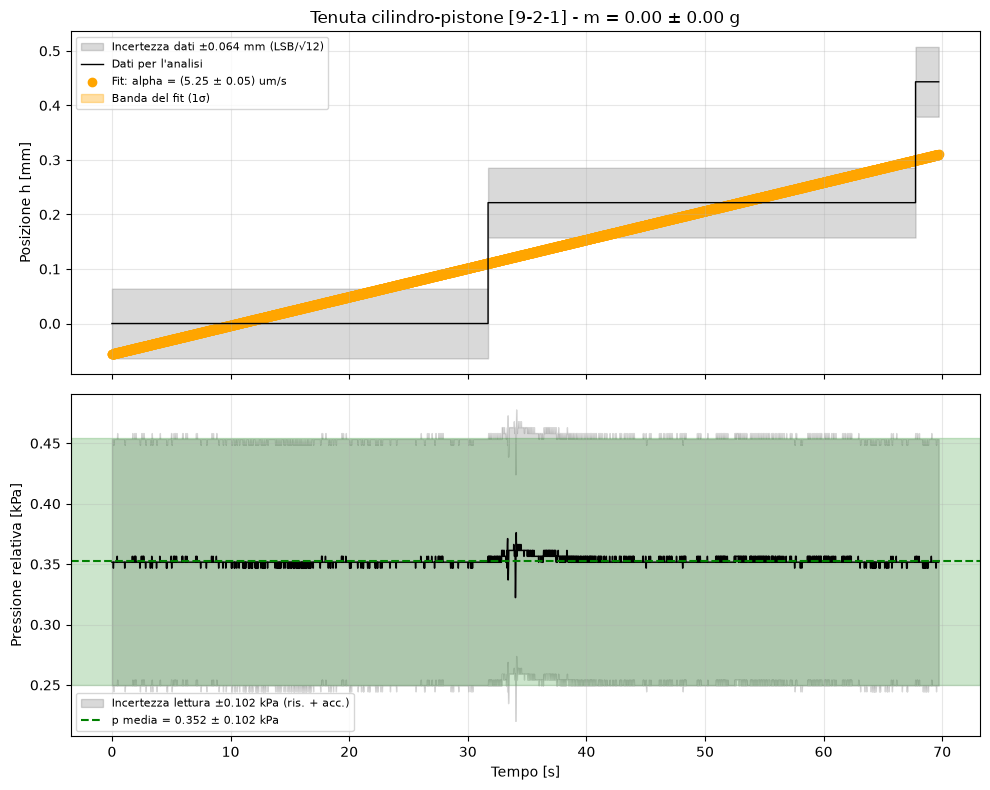

  9-2-2: m = 83.65 ± 0.32 g | mg/S = 0.9892 ± 0.0038 kPa | p misurata = 1.2453 ± 0.1020 kPa
         alpha = (14.681 ± 0.055) um/s [ris 0.055, acc 0.000] | beta = 0.7307 ± 0.0027 cm^3/min


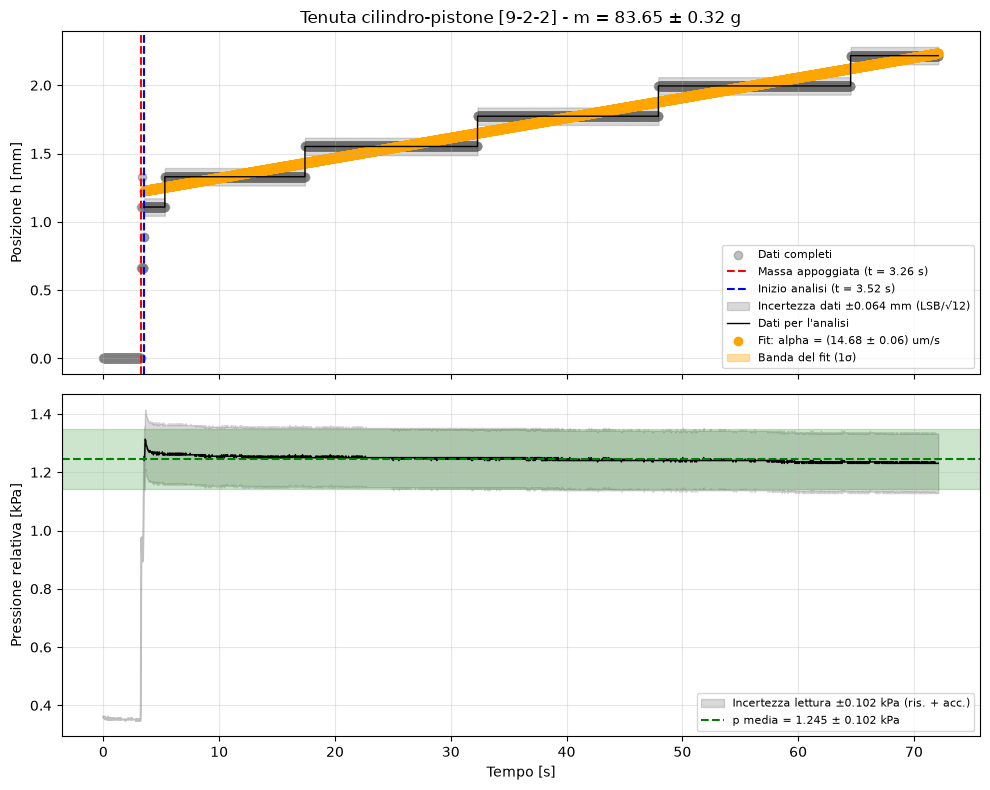

  9-2-3: m = 167.80 ± 0.62 g | mg/S = 1.9843 ± 0.0073 kPa | p misurata = 2.1630 ± 0.1020 kPa
         alpha = (23.797 ± 0.054) um/s [ris 0.054, acc 0.000] | beta = 1.1845 ± 0.0027 cm^3/min


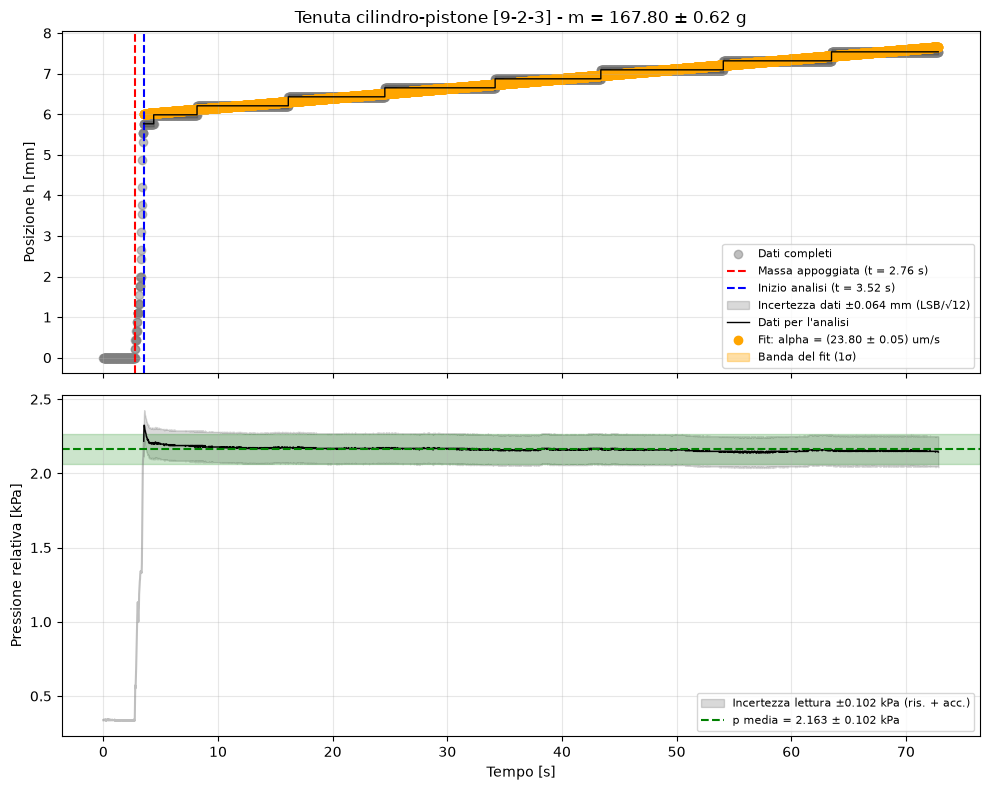

  9-2-4: m = 250.98 ± 0.91 g | mg/S = 2.9679 ± 0.0108 kPa | p misurata = 3.0925 ± 0.1020 kPa
         alpha = (31.213 ± 0.066) um/s [ris 0.066, acc 0.000] | beta = 1.5536 ± 0.0033 cm^3/min


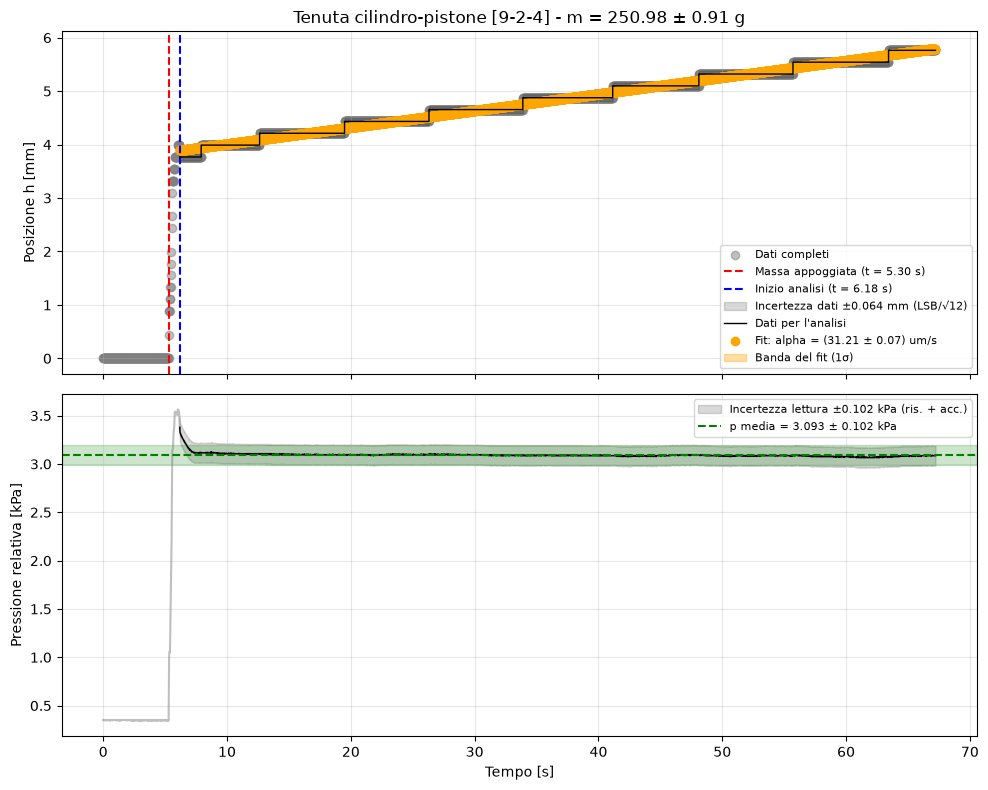

  9-2-5: m = 333.00 ± 1.21 g | mg/S = 3.9378 ± 0.0143 kPa | p misurata = 3.9958 ± 0.1020 kPa
         alpha = (41.021 ± 0.066) um/s [ris 0.066, acc 0.000] | beta = 2.0418 ± 0.0033 cm^3/min


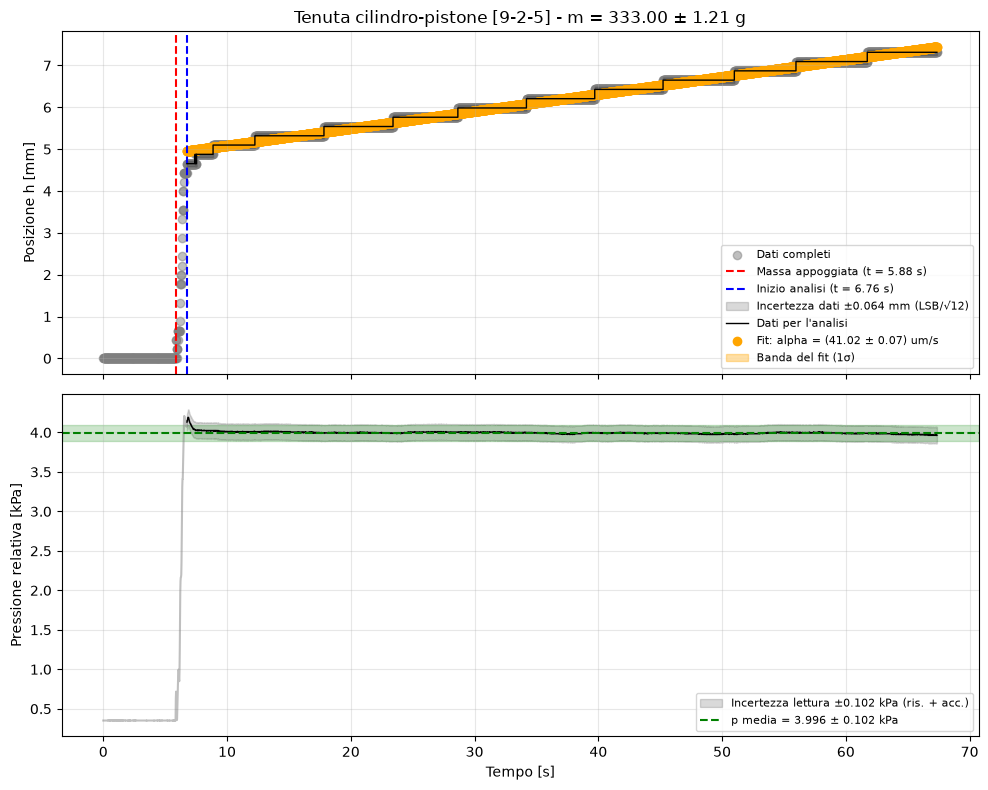

  Contributi a sigma_beta_eff: sigma_beta = [0.00268 0.00275 0.0027  0.00327 0.00331], omega*sigma_dp = [0.      0.00172 0.00327 0.00484 0.00642] cm^3/min
  omega = 0.4486 ± 0.0057 cm^3/(kPa min) [fit 0.0015, superficie S 0.0055]
  c     = 0.2714 ± 0.0023 cm^3/min
  chi2 / gdl = 137.46 / 3
  p misurata - mg/S = [0.352 0.256 0.179 0.125 0.058] kPa (media 0.194 kPa -> m_pistone ≈ 16.4 g)


In [49]:
for nome_serie, files in SERIE.items():
    masse = MASSE_g[nome_serie]
    sigma_masse = SIGMA_MASSE_g[nome_serie]

    print(f"\n{nome_serie}")
    dati = np.array([analizza_file(nome, con_massa=(k != 0),
                                   massa_g=masse[k], sigma_massa_g=sigma_masse[k])
                     for k, nome in enumerate(files)])
    dp, sigma_dp, beta, sigma_beta, p_mis, sigma_p_mis = dati.T

    # FIT beta = omega * dp + c
    omega, c, cov_fit, chi2, sigma_eff = fit_lineare_xy(dp, sigma_dp, beta, sigma_beta)
    sigma_omega_stat, sigma_c = np.sqrt(np.diag(cov_fit))

    # S compare in beta (∝ S) e in dp (∝ 1/S) -> omega ∝ S^2: errore sistematico comune
    sigma_omega_S = abs(omega) * 2 * SIGMA_S / S
    sigma_omega = np.sqrt(sigma_omega_stat**2 + sigma_omega_S**2)

    print(f"  Contributi a sigma_beta_eff: sigma_beta = {np.round(sigma_beta, 5)}, "
          f"omega*sigma_dp = {np.round(abs(omega) * sigma_dp, 5)} cm^3/min")
    print(f"  omega = {omega:.4f} ± {sigma_omega:.4f} cm^3/(kPa min) "
          f"[fit {sigma_omega_stat:.4f}, superficie S {sigma_omega_S:.4f}]")
    print(f"  c     = {c:.4f} ± {sigma_c:.4f} cm^3/min")
    print(f"  chi2 / gdl = {chi2:.2f} / {len(dp) - 2}")

    # controllo: p misurata - mg/S dovrebbe essere ~ costante (peso del pistone / S)
    diff = p_mis - dp
    print(f"  p misurata - mg/S = {np.round(diff, 3)} kPa "
          f"(media {diff.mean():.3f} kPa -> m_pistone ≈ {diff.mean()*1e3*S/g*1e3:.1f} g)")

    risultati[nome_serie] = dict(dp=dp, beta=beta, sigma_eff=sigma_eff,
                                 omega=omega, c=c, cov_fit=cov_fit,
                                 sigma_omega=sigma_omega,
                                 sigma_omega_stat=sigma_omega_stat)

### Confronto
Le due serie sono riportate nello stesso grafico $\beta$ in funzione di $\Delta p$:
- punti con barre d'errore $\sigma_{\beta,\text{eff}}$, che comprendono anche l'incertezza su $\Delta p$ propagata;
- rette di fit;
- bande a $1\sigma$, calcolate con `banda_fit` dalla matrice di covarianza del fit.

Le rette sono estese fino a $\Delta p = 0$ per mostrare l'intercetta $c$.


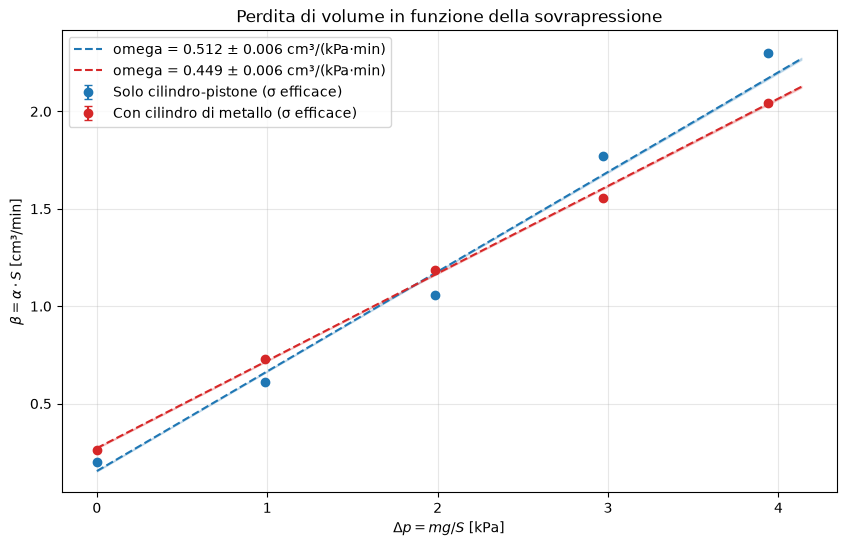

In [50]:
plt.figure(figsize=(10, 6))
for (nome_serie, r), col in zip(risultati.items(), ['tab:blue', 'tab:red']):
    plt.errorbar(r['dp'], r['beta'], yerr=r['sigma_eff'],
                 fmt='o', color=col, capsize=3,
                 label=f"{nome_serie} (σ efficace)")

    x_fit = np.linspace(0, r['dp'].max() * 1.05, 200)
    y_fit = r['omega'] * x_fit + r['c']
    s_fit = banda_fit(x_fit, r['cov_fit'])

    plt.plot(x_fit, y_fit, color=col, linestyle='--',
             label=f"omega = {r['omega']:.3f} ± {r['sigma_omega']:.3f} cm³/(kPa·min)")
    plt.fill_between(x_fit, y_fit - s_fit, y_fit + s_fit, color=col, alpha=0.2)
    
plt.title("Perdita di volume in funzione della sovrapressione")
plt.xlabel(r"$\Delta p = mg/S$ [kPa]")
plt.ylabel(r"$\beta = \alpha \cdot S$ [cm³/min]")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(f"{CARTELLA}/confronto_omega.png", dpi=300)
plt.show()

### Compatibilità tra i due $\omega$
Si confrontano i due valori di $\omega$ con il test di compatibilità
$$z = \frac{|\omega_1 - \omega_2|}{\sqrt{\sigma_{\omega_1,\text{fit}}^2 + \sigma_{\omega_2,\text{fit}}^2}}.$$
Al denominatore si usano solo le incertezze **del fit**, senza il contributo di $S$: il pistone è lo stesso in entrambe le serie, quindi un errore su $S$ sposta tutti e due gli $\omega$ dello stesso fattore $(1 \pm 2\sigma_S/S)$. Nella differenza non conta.

Come si legge $z$:
- $z \lesssim 2$: i due valori sono compatibili, e collegare il cilindro di metallo non cambia la tenuta in modo rilevabile;
- $z$ grande: le due configurazioni hanno tenute diverse. Il cilindro di metallo aggiunge volume e giunzioni attraverso cui l'aria può uscire. Bisogna però controllare anche che le incertezze su $\alpha$ non siano sottostimate (vedi la nota nell'analisi del singolo file).


In [51]:
(n1, r1), (n2, r2) = risultati.items()
# stesso pistone per entrambe le serie: l'incertezza su S e' comune e non entra nel confronto
z = abs(r1['omega'] - r2['omega']) / np.sqrt(r1['sigma_omega_stat']**2 + r2['sigma_omega_stat']**2)
print(f"\nCompatibilita' tra gli omega: z = {z:.2f} sigma")


Compatibilita' tra gli omega: z = 29.48 sigma
